**Wojciech Olejnik**

# **Drzewo decyzyjne**

Przygotowanie struktury liścia drzewa, które zawierać będzie referacje na lewą i prawą gałąź :

In [27]:
import numpy as np
from TreeNode import Node
from sklearn import preprocessing
import pandas as pd
from sklearn import preprocessing
import time
from sklearn.tree import export_graphviz
import warnings; warnings.simplefilter('ignore')
from IPython.display import Image

In [17]:
class TreeNode:
    def __init__(self, gini, number_samples, number_samples_per_class, predicted_class):
        self.gini = gini
        self.number_samples = number_samples
        self.number_samples_per_class = number_samples_per_class
        self.predicted_class = predicted_class
        self.id = 0
        self.decison = 0
        self.left = None
        self.right = None

Implementacja algorytmu budowy drzewa decyzyjnego :

In [18]:
class DecisionTree:
    def __init__(self, max_depth=0):
        self.max_depth = max_depth

    def gini(self, y):
        return 1.0 - np.sum(np.power((np.sum(y == c) / y.size), 2) for c in range(self.n_classes_))
    
    def rpart(self, X, y, depth=0, node_id=0):

        # Population for each class in current node. The predicted class is the one with largest population.
        number_samples_per_class = np.unique([np.sum(y == i) for i in range(self.n_classes_)])
        predicted_class = np.argmax(number_samples_per_class)

        node = Node(gini=self.gini(y), number_samples=y.size, number_samples_per_class=number_samples_per_class,
                    predicted_class=predicted_class)

        if depth < self.max_depth:
            idx, decision = self.split(X, y)
            if idx is not 0:
                indices_left = X[:, idx] < decision
                X_left = X[indices_left]
                y_left = y[indices_left]
                X_right = X[~indices_left]
                y_right = y[~indices_left]
                node.feature_index = idx
                node.decison = decision
                node.left = self.rpart(X_left, y_left, depth + 1, node_id + 1)
                node.right = self.rpart(X_right, y_right, depth + 1, node_id + 1)
        return node
    
    
    def split(self, X, y):
        
        le = preprocessing.LabelEncoder()
        if y.size <= 1:
            return None, None
        
        num_parent = [np.sum(y == c) for c in range(self.n_classes_)]

        # calculate ginie of the current node
        best_gini = 1.0 - sum((n / y.size) ** 2 for n in num_parent)
        best_id, best_decision = 0, None
        
        for idx in range(self.n_features_):
            tmp = le.fit(X[:, idx])
            tmp2 = le.classes_
            feature_to_binary = le.transform(X[:, idx])

            decisions, classes = zip(*sorted(zip(feature_to_binary, y)))
            num_left = [0] * self.n_classes_
            num_right = num_parent.copy()
            for i in range(1, y.size):
                c = classes[i - 1]
                num_left[c] = num_left[c] + 1
                num_right[c] = num_right[c] - 1
                gini_left = 1.0 - sum((num_left[x] / i) ** 2 for x in range(self.n_classes_))
                gini_right = 1.0 - sum((num_right[x] / (y.size - i)) ** 2 for x in range(self.n_classes_))

                # Average of children gini
                gini = (i * gini_left + (y.size - i) * gini_right) / y.size
                if decisions[i] == decisions[i - 1]:
                    continue
                if gini < best_gini:
                    best_gini = gini
                    best_id = idx
                    best_decision = (decisions[i] + decisions[i - 1]) / 2  # midpoint

        return best_id, best_decision
    
    def fit(self, X, y):
        self.n_classes_ = len(y)
        self.n_features_ = X.shape[1]
        self.tree_ = self.rpart(X, y)

    def predict_node(self, args):
        node = self.tree_
        while node.left:
            if args[node.feature_index] < node.threshold:
                node = node.left
            else:
                node = node.right
        return node.predicted_class

    def predict(self, X):
        return [self.predict_node(x) for x in X]
    
    def print_tree(self, feature_names, class_names, show_details=True):
        self.tree_.debug(feature_names, class_names, show_details)

# Preprocessing danych

In [19]:
df = pd.read_csv('./zoo.csv')

Usuwamy atrybuty legs, animal i type, bo będzie to nasza zmienna decyzyjna.

In [20]:
y = df['type'].to_numpy()
X = df.drop(columns=['legs', 'animal', 'type']).to_numpy()

In [21]:
y

array(['mammal', 'mammal', 'fish', 'mammal', 'mammal', 'mammal', 'mammal',
       'fish', 'fish', 'mammal', 'mammal', 'bird', 'fish', 'invertebrate',
       'invertebrate', 'invertebrate', 'bird', 'mammal', 'fish', 'mammal',
       'bird', 'bird', 'mammal', 'bird', 'insect', 'amphibian',
       'amphibian', 'mammal', 'mammal', 'mammal', 'insect', 'mammal',
       'mammal', 'bird', 'fish', 'mammal', 'mammal', 'bird', 'fish',
       'insect', 'insect', 'bird', 'insect', 'bird', 'mammal', 'mammal',
       'invertebrate', 'mammal', 'mammal', 'mammal', 'mammal', 'insect',
       'amphibian', 'invertebrate', 'mammal', 'mammal', 'bird', 'bird',
       'bird', 'bird', 'fish', 'fish', 'reptile', 'mammal', 'mammal',
       'mammal', 'mammal', 'mammal', 'mammal', 'mammal', 'mammal', 'bird',
       'invertebrate', 'fish', 'mammal', 'mammal', 'reptile',
       'invertebrate', 'bird', 'bird', 'reptile', 'invertebrate', 'fish',
       'bird', 'mammal', 'invertebrate', 'fish', 'bird', 'insect',
      

In [22]:
X

array([[ True, False, False, ..., False, False,  True],
       [ True, False, False, ...,  True, False,  True],
       [False, False,  True, ...,  True, False, False],
       ...,
       [ True, False, False, ...,  True, False,  True],
       [False, False,  True, ..., False, False, False],
       [False,  True,  True, ...,  True, False, False]])

In [23]:
le = preprocessing.LabelEncoder()
tmp_y = le.fit(y)
tmp_y2 = le.classes_
classes_to_binary = le.transform(y)

Na podstawie danych wejściowych X oraz klas y znaleźć atrybut o najmniejszej nieczystości.

In [24]:
target_names = pd.unique(y)
target_names

array(['mammal', 'fish', 'bird', 'invertebrate', 'insect', 'amphibian',
       'reptile'], dtype=object)

In [25]:
feature_names = df.drop(['type'], axis=1)
feature_names

,animal,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
0,aardvark,True,False,False,True,False,False,True,True,True,True,False,False,4,False,False,True
1,antelope,True,False,False,True,False,False,False,True,True,True,False,False,4,True,False,True
2,bass,False,False,True,False,False,True,True,True,True,False,False,True,0,True,False,False
3,bear,True,False,False,True,False,False,True,True,True,True,False,False,4,False,False,True
4,boar,True,False,False,True,False,False,True,True,True,True,False,False,4,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,wallaby,True,False,False,True,False,False,False,True,True,True,False,False,2,True,False,True
97,wasp,True,False,True,False,True,False,False,False,False,True,True,False,6,False,False,False
98,wolf,True,False,False,True,False,False,True,True,True,True,False,False,4,True,False,True
99,worm,False,False,True,False,False,False,False,False,False,True,False,False,0,False,False,False


**Generowanie pełnego drzewa**

In [28]:
start = time.time()
clf = DecisionTree()
clf.fit(X, classes_to_binary)
clf.print_tree(feature_names.columns, target_names, True)
end = time.time()

# Draw graph
dot_data = export_graphviz(clf, out_file=None, 
                                feature_names=feature_names.columns,  
                                class_names=target_names,
                                filled=True)


graph = graphviz.Source(dot_data, format="png") 


print(f'{end - start}')

0.006822109222412109


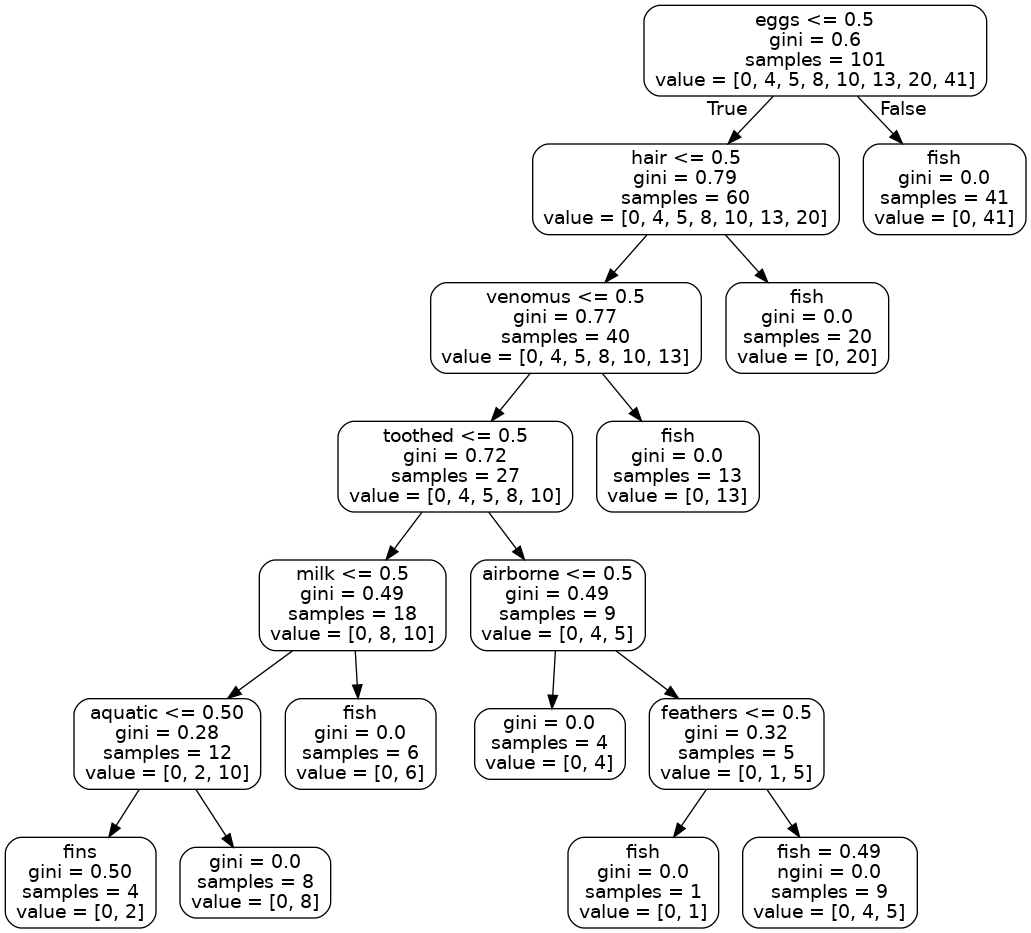

In [13]:
Image("./mytree.png")

In [34]:
print(f'Predict : {clf.predict(X)}')

Predict : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


**Przycinanie drzewa ze względu na głebokość**

In [29]:
start = time.time()
clf = DecisionTree(max_depth=2)
clf.fit(X, classes_to_binary)
end = time.time()
print(f'{end - start}')

0.2578773498535156


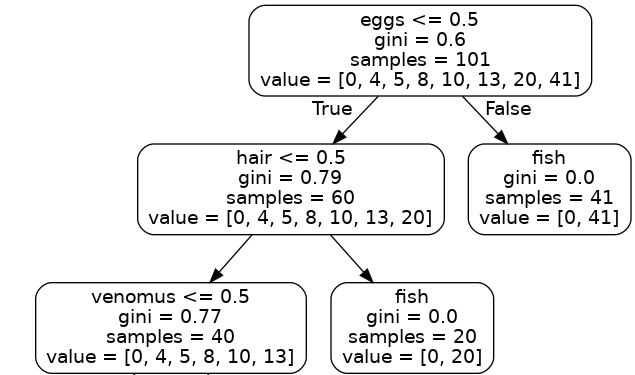

In [15]:
Image("./pluring.png")

# Porównanie własnej implementacji drzewa z drzewem z pakietu sklearn

In [57]:
from sklearn import tree
t1 = time.time()
clf = tree.DecisionTreeClassifier(criterion='gini')
clf.fit(X, y)
time.time() - t1

0.005857706069946289

Tworzenie drzewa z pakietu _sklearn_ wykonało budowę drzewa szybsze.

**Wizualizacja drzewa decyzyjnego zbioru zoo.csv, które zostało wygenerowane za pomocą _sklearn_**

In [36]:
from pydotplus import graph_from_dot_data
from sklearn.tree import export_graphviz
from IPython.display import Image
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


animal = pd.read_csv('./zoo.csv')

X = animal.iloc[:,1:17]
y = animal.iloc[:,17]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

# Declare and train the model
t1 = time.time()
clf = DecisionTreeClassifier(random_state = 0,criterion='gini')
clf.fit(X_train, y_train)
time.time() - t1
y_pred_DecisionTreeClassifier = clf.predict(X_test)

scores = []
score = accuracy_score(y_pred_DecisionTreeClassifier,y_test)
scores.append(score)

global tree  
# Get the tree
tree = []
tree = clf

dot_data = export_graphviz(tree,
                           filled=True, 
                           rounded=True,
                           class_names=["1","2","3","4","5","6","7" ],
                           feature_names=X.columns,
                           out_file="tree.dot") 

graph = graph_from_dot_data(dot_data) 

Image(dot_data.create_png()) 

0.00016379356384277344

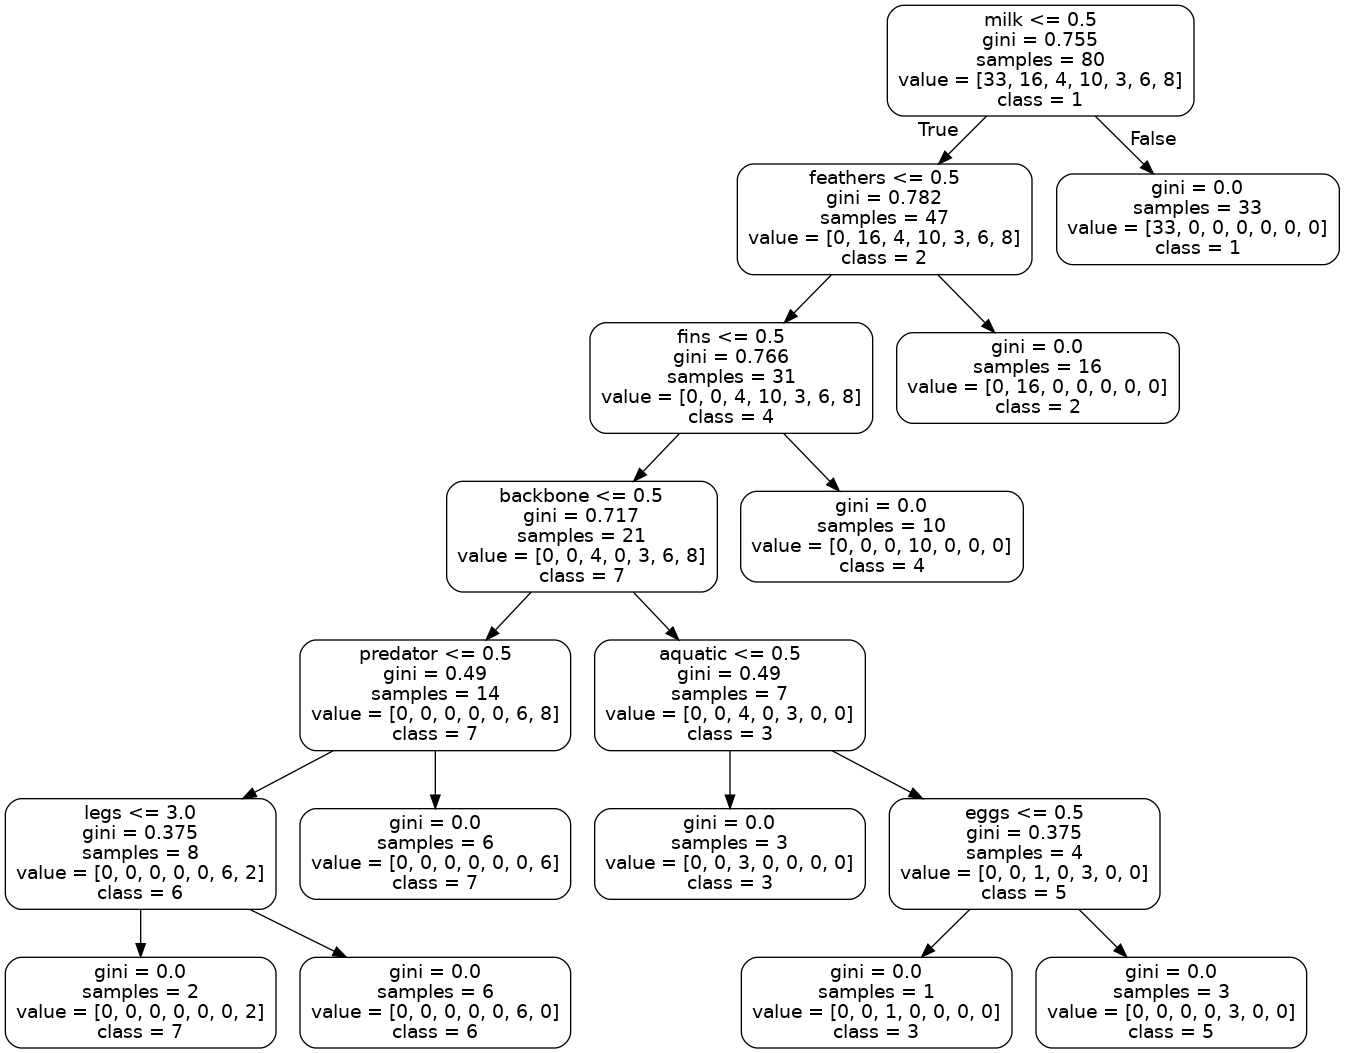

In [37]:
Image("./tree.png")